In [1]:
# Load dataset
from datasets import load_dataset

ds = load_dataset("cornell-movie-review-data/rotten_tomatoes")
ds

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

...

test.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8530 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
})

# Część 1

### 1.1

In [2]:
import re
import unicodedata
from collections import Counter


UNK_TOKEN = '<UNK>'
TOKEN_PATTERN = re.compile(r"[^\W_]+(?:'[^\W_]+)*")


def normalize_text(text):
    return unicodedata.normalize('NFKC', text).casefold()


def tokenize(text):
    return TOKEN_PATTERN.findall(normalize_text(text))

# Unknown tokens are saved as the UNK_TOKEN in the vocabulary
def build_vocabulary(training_texts):
    tokens = {token for text in training_texts for token in tokenize(text)}
    vocabulary = {UNK_TOKEN: 0}
    vocabulary.update({token: index for index, token in enumerate(sorted(tokens), start=1)})
    return vocabulary

In [3]:
train_texts = ds['train']['text']
vocabulary = build_vocabulary(train_texts)

vocabulary

{'<UNK>': 0,
 '00': 1,
 '007': 2,
 '1': 3,
 '10': 4,
 '100': 5,
 '101': 6,
 '102': 7,
 '104': 8,
 '105': 9,
 '10th': 10,
 '11': 11,
 '110': 12,
 '112': 13,
 '117': 14,
 '11th': 15,
 '12': 16,
 '123': 17,
 '125': 18,
 '127': 19,
 '129': 20,
 '12th': 21,
 '13': 22,
 '13th': 23,
 '14': 24,
 '146': 25,
 '15': 26,
 '15th': 27,
 '16': 28,
 '163': 29,
 '17': 30,
 '170': 31,
 '179': 32,
 "1790's": 33,
 '18': 34,
 '180': 35,
 '1873': 36,
 '1899': 37,
 '18th': 38,
 '19': 39,
 '1915': 40,
 "1920's": 41,
 '1930s': 42,
 '1933': 43,
 '1934': 44,
 '1940s': 45,
 '1949': 46,
 '1950': 47,
 "1950's": 48,
 '1950s': 49,
 '1952': 50,
 '1953': 51,
 '1954': 52,
 '1955': 53,
 '1957': 54,
 '1958': 55,
 '1960': 56,
 '1960s': 57,
 '1962': 58,
 '1967': 59,
 '1970s': 60,
 '1972': 61,
 '1973': 62,
 '1975': 63,
 '1978': 64,
 '1979': 65,
 '1980': 66,
 "1980's": 67,
 '1980s': 68,
 '1982': 69,
 "1982's": 70,
 "1983's": 71,
 '1984': 72,
 '1986': 73,
 "1988's": 74,
 '1989': 75,
 '1990': 76,
 '1991': 77,
 '1992': 78,
 "199

### 1.2

In [4]:
def bag_of_words(text, vocabulary):
    vector = {}
    for token in tokenize(text):
        index = vocabulary.get(token, vocabulary[UNK_TOKEN])
        vector[index] = vector.get(index, 0) + 1
    return vector

In [7]:
import random
import torch

seed = 42
random.seed(seed)
torch.manual_seed(seed)

seed

42

In [6]:
rand_train_texts = random.sample(train_texts, 5)
for text in rand_train_texts:
    bow_vector = bag_of_words(text, vocabulary)
    print(text, bow_vector)

a touching , sophisticated film that almost seems like a documentary in the way it captures an italian immigrant family on the brink of major changes . {173: 2, 15474: 1, 14033: 1, 5737: 1, 15182: 1, 587: 1, 13258: 1, 8824: 1, 4393: 1, 7613: 1, 15186: 2, 16581: 1, 8103: 1, 2263: 1, 682: 1, 8107: 1, 7531: 1, 5523: 1, 10461: 1, 1954: 1, 10405: 1, 9158: 1, 2449: 1}
starts off with a bang , but then fizzles like a wet stick of dynamite at the very end . it's still worth a look . {14340: 1, 10406: 1, 16840: 1, 173: 3, 1271: 1, 2110: 1, 15204: 1, 5813: 1, 8824: 1, 16676: 1, 14403: 1, 10405: 1, 4673: 1, 1042: 1, 15186: 1, 16323: 1, 4940: 1, 8106: 1, 14414: 1, 16932: 1, 8961: 1}
sometimes there are very , very good reasons for certain movies to be sealed in a jar and left on a remote shelf indefinitely . {14013: 1, 15212: 1, 880: 1, 16323: 2, 6509: 1, 12154: 1, 5960: 1, 2414: 1, 9878: 1, 15386: 1, 1360: 1, 13206: 1, 7613: 1, 173: 2, 8171: 1, 701: 1, 8703: 1, 10461: 1, 12409: 1, 13488: 1, 7672:

### 1.3 & 1.4

In [10]:
from torch import nn
from torch.utils.data import DataLoader

def bow_batch(batch):
    features = torch.zeros((len(batch), len(vocabulary)), dtype=torch.float32)
    for row, (vector, _) in enumerate(batch):
        for index, count in vector.items():
            features[row, index] = count
    labels = torch.tensor([label for _, label in batch], dtype=torch.float32)
    return features, labels.unsqueeze(1)


training_data = [
    (bag_of_words(text, vocabulary), label) 
    for text, label in zip(train_texts, ds['train']['label'])
]
train_loader = DataLoader(
    training_data, batch_size=64, shuffle=True, collate_fn=bow_batch
)

validation_data = [
    (bag_of_words(text, vocabulary), label) 
    for text, label in zip(ds['validation']['text'], ds['validation']['label'])
]
val_loader = DataLoader(
    validation_data, batch_size=64, shuffle=False, collate_fn=bow_batch
)

model = nn.Linear(len(vocabulary), 1)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def evaluate(eval_model, data_loader):
    eval_model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for features, labels in data_loader:
            logits = eval_model(features)
            probabilities = torch.sigmoid(logits)
            loss = criterion(probabilities, labels)
            total_loss += loss.item() * len(labels)
            predictions = (probabilities >= 0.5).float()
            correct += (predictions == labels).sum().item()
            total += len(labels)
    return total_loss / total, correct / total

train_accuracies = []
val_accuracies = []
best_val_accuracy = 0.0
checkpoint_path = 'best_checkpoint.pt'

for epoch in range(100):
    model.train()
    total_loss = 0.0
    train_correct = 0
    for features, labels in train_loader:
        optimizer.zero_grad()
        logits = model(features)
        probabilities = torch.sigmoid(logits)
        loss = criterion(probabilities, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * len(labels)
        predictions = (probabilities >= 0.5).float()
        train_correct += (predictions == labels).sum().item()

    train_loss = total_loss / len(training_data)
    train_accuracy = train_correct / len(training_data)
    train_accuracies.append(train_accuracy)

    val_loss, val_accuracy = evaluate(model, val_loader)
    val_accuracies.append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(model.state_dict(), checkpoint_path)

    print(f'Epoch {epoch + 1:3d}: BCE = {train_loss:.4f}, Train Acc = {train_accuracy:.4f}, Val Acc = {val_accuracy:.4f}')

print()
print(f'Best Validation Accuracy: {best_val_accuracy:.4f} (saved to {checkpoint_path})')

Epoch   1: BCE = 0.6763, Train Acc = 0.6559, Val Acc = 0.7008
Epoch   2: BCE = 0.6286, Train Acc = 0.7742, Val Acc = 0.7158
Epoch   3: BCE = 0.5893, Train Acc = 0.8077, Val Acc = 0.7289
Epoch   4: BCE = 0.5562, Train Acc = 0.8295, Val Acc = 0.7326
Epoch   5: BCE = 0.5275, Train Acc = 0.8440, Val Acc = 0.7383
Epoch   6: BCE = 0.5026, Train Acc = 0.8560, Val Acc = 0.7430
Epoch   7: BCE = 0.4803, Train Acc = 0.8702, Val Acc = 0.7392
Epoch   8: BCE = 0.4604, Train Acc = 0.8787, Val Acc = 0.7430
Epoch   9: BCE = 0.4421, Train Acc = 0.8871, Val Acc = 0.7430
Epoch  10: BCE = 0.4254, Train Acc = 0.8937, Val Acc = 0.7458
Epoch  11: BCE = 0.4101, Train Acc = 0.8995, Val Acc = 0.7477
Epoch  12: BCE = 0.3960, Train Acc = 0.9063, Val Acc = 0.7514
Epoch  13: BCE = 0.3828, Train Acc = 0.9115, Val Acc = 0.7542
Epoch  14: BCE = 0.3705, Train Acc = 0.9169, Val Acc = 0.7570
Epoch  15: BCE = 0.3590, Train Acc = 0.9211, Val Acc = 0.7608
Epoch  16: BCE = 0.3481, Train Acc = 0.9257, Val Acc = 0.7589
Epoch  1

{'probability': 0.9282111525535583, 'label': 1}

### 1.5

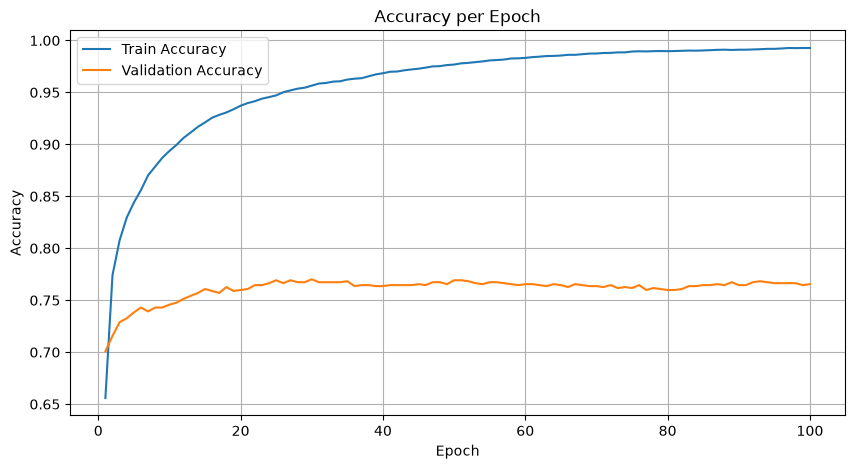

In [11]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_accuracies) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs, train_accuracies, label='Train Accuracy')
plt.plot(epochs, val_accuracies, label='Validation Accuracy')
plt.title('Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
test_data = [
    (bag_of_words(text, vocabulary), label) 
    for text, label in zip(ds['test']['text'], ds['test']['label'])
]
test_loader = DataLoader(
    test_data, batch_size=64, shuffle=False, collate_fn=bow_batch
)

model.load_state_dict(torch.load('best_checkpoint.pt'))
model.eval()

test_loss, test_accuracy = evaluate(model, test_loader)
print(f'Test BCE Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.4f}')

Test BCE Loss: 0.4601
Test Accuracy: 0.7880


In [13]:
def predict(text):
    tokens = tokenize(text)
    bow = bag_of_words(text, vocabulary)
    
    features = torch.zeros((1, len(vocabulary)), dtype=torch.float32)
    for index, count in bow.items():
        features[0, index] = count
        
    model.eval()
    with torch.no_grad():
        logits = model(features)
        prob = torch.sigmoid(logits).item()
        
    prediction = "POSITIVE" if prob >= 0.5 else "NEGATIVE"
    return prediction, prob, tokens

test_cases = [
    # Negation
    ("The movie is not good, it is actually quite bad.", "NEGATIVE"),
    ("The movie is good, not bad.", "POSITIVE"),
    
    # Sarcasm
    ("A true masterpiece of wasting the audience's time and money.", "NEGATIVE"),
    
    # Contrastive conjunction ('but')
    ("The cinematography was breathtaking and the actors were phenomenal, but the plot was completely incoherent and boring.", "NEGATIVE"),
    
    # Typographical curly quote vs ASCII quote
    ("don't like it", "NEGATIVE"),
    ("don’t like it", "NEGATIVE"),
    
    # Out-of-vocabulary slang
    ("An absolute snoozefest from start to finish.", "NEGATIVE"),
]

for text, expected in test_cases:
    prediction, prob, tokens = predict(text)
    print(f"Text: {text}")
    print(f"Expected: {expected}")
    print(f"Prediction: {prediction}, Probability: {prob:.4f}")
    print(f"Tokens: {tokens}")
    print()

Text: The movie is not good, it is actually quite bad.
Expected: NEGATIVE
Prediction: NEGATIVE, Probability: 0.2607
Tokens: ['the', 'movie', 'is', 'not', 'good', 'it', 'is', 'actually', 'quite', 'bad']

Text: The movie is good, not bad.
Expected: POSITIVE
Prediction: NEGATIVE, Probability: 0.2531
Tokens: ['the', 'movie', 'is', 'good', 'not', 'bad']

Text: A true masterpiece of wasting the audience's time and money.
Expected: NEGATIVE
Prediction: POSITIVE, Probability: 0.6392
Tokens: ['a', 'true', 'masterpiece', 'of', 'wasting', 'the', "audience's", 'time', 'and', 'money']

Text: The cinematography was breathtaking and the actors were phenomenal, but the plot was completely incoherent and boring.
Expected: NEGATIVE
Prediction: NEGATIVE, Probability: 0.0623
Tokens: ['the', 'cinematography', 'was', 'breathtaking', 'and', 'the', 'actors', 'were', 'phenomenal', 'but', 'the', 'plot', 'was', 'completely', 'incoherent', 'and', 'boring']

Text: don't like it
Expected: NEGATIVE
Prediction: NEGAT

**Podsumowanie**: Ma problem z niektorymi negacjami, tekst poza slownikiem bywa problematyczny

# Część 2

### 2.1 

In [14]:
from collections import Counter, defaultdict

END_OF_WORD = '</w>'

def format_word_for_bpe(word: str) -> str:
    return ' '.join(list(word)) + f' {END_OF_WORD}'

def build_bpe_word_counts(texts):
    word_counts = Counter()
    for text in texts:
        for word in tokenize(text):
            formatted_word = format_word_for_bpe(word)
            word_counts[formatted_word] += 1
    return word_counts

In [17]:
bpe_word_counts = build_bpe_word_counts(train_texts)

print(f"Unique words: {len(bpe_word_counts)}")

Unique words: 17103


In [18]:
print("10 most common words: ")
for word, count in bpe_word_counts.most_common(10):
    print(f"{word!r:<25} : {count}")

10 most common words: 
't h e </w>'              : 8115
'a </w>'                  : 5904
'a n d </w>'              : 4971
'o f </w>'                : 4886
't o </w>'                : 3447
'i s </w>'                : 2713
'i n </w>'                : 2146
't h a t </w>'            : 1977
'i t </w>'                : 1805
'a s </w>'                : 1412


### 2.2

In [20]:
def get_stats(vocab):
    pairs = defaultdict(int)
    for word, freq in vocab.items():
        symbols = word.split()
        for i in range(len(symbols) - 1):
            pairs[(symbols[i], symbols[i + 1])] += freq
    return pairs

In [21]:
initial_pairs = get_stats(bpe_word_counts)
best_initial_pair = max(initial_pairs, key=initial_pairs.get)

print(f"Total number of unique symbol pairs: {len(initial_pairs)}")
print(f"Most frequent initial pair: {best_initial_pair} (occurrences: {initial_pairs[best_initial_pair]})\n")

print("Top 10 most frequent symbol pairs:")
sorted_pairs = sorted(initial_pairs.items(), key=lambda item: item[1], reverse=True)[:10]
for pair, freq in sorted_pairs:
    print(f"{str(pair):<25} : {freq}")

Total number of unique symbol pairs: 856
Most frequent initial pair: ('e', '</w>') (occurrences: 28497)

Top 10 most frequent symbol pairs:
('e', '</w>')             : 28497
('s', '</w>')             : 24777
('t', 'h')                : 18467
('t', '</w>')             : 16842
('i', 'n')                : 15125
('h', 'e')                : 12913
('d', '</w>')             : 12889
('a', 'n')                : 12352
('y', '</w>')             : 12076
('e', 'r')                : 11408


### 2.3

In [22]:
def merge_vocab(pair, v_in):
    v_out = {}
    bigram = re.escape(' '.join(pair))
    p = re.compile(r'(?<!\S)' + bigram + r'(?!\S)')
    replacement = ''.join(pair)
    p0, p1 = pair
    
    for word, freq in v_in.items():
        if p0 in word and p1 in word:
            w_out = p.sub(replacement, word)
            v_out[w_out] = freq
        else:
            v_out[word] = freq
    return v_out

In [23]:
toy_vocab = {
    'l o w </w>': 5,
    'l o w e s t </w>': 2,
    'n e w e r </w>': 6,
    'w i d e r </w>': 3,
    'n e w </w>': 2
}

toy_pairs = get_stats(toy_vocab)
best_toy_pair = max(toy_pairs, key=toy_pairs.get)
merged_toy_vocab = merge_vocab(best_toy_pair, toy_vocab)

print(f"Most frequent pair in toy example: {best_toy_pair}")
print("Vocabulary before merging:")
print(toy_vocab)
print("\nVocabulary after merging:")
print(merged_toy_vocab)

Most frequent pair in toy example: ('e', 'r')
Vocabulary before merging:
{'l o w </w>': 5, 'l o w e s t </w>': 2, 'n e w e r </w>': 6, 'w i d e r </w>': 3, 'n e w </w>': 2}

Vocabulary after merging:
{'l o w </w>': 5, 'l o w e s t </w>': 2, 'n e w er </w>': 6, 'w i d er </w>': 3, 'n e w </w>': 2}


### 2.4

In [24]:
def train_bpe(word_counts, num_merges=300):
    vocab = dict(word_counts)
    merges = []
    bpe_ranks = {}
    
    for i in range(num_merges):
        pairs = get_stats(vocab)
        if not pairs:
            print(f"No more pairs to merge after {i} steps.")
            break
            
        best_pair = max(pairs, key=pairs.get)
        vocab = merge_vocab(best_pair, vocab)
        
        merges.append(best_pair)
        bpe_ranks[best_pair] = i
        
        if (i + 1) % 50 == 0 or i == 0:
            print(f"Step {i + 1:3d}/{num_merges}: Merged {best_pair} (frequency: {pairs[best_pair]})")
            
    return merges, bpe_ranks, vocab

In [25]:
NUM_MERGES = 300
merges, bpe_ranks, trained_bpe_vocab = train_bpe(bpe_word_counts, num_merges=NUM_MERGES)

print(f"\nTraining completed. Learned {len(merges)} merge rules.")

Step   1/300: Merged ('e', '</w>') (frequency: 28497)
Step  50/300: Merged ('a', 's</w>') (frequency: 2302)
Step 100/300: Merged ('p', 'l') (frequency: 1172)
Step 150/300: Merged ('e', 'd') (frequency: 734)
Step 200/300: Merged ('oo', 'd</w>') (frequency: 532)
Step 250/300: Merged ('m', 'i') (frequency: 390)
Step 300/300: Merged ('an', 'd') (frequency: 308)

Training completed. Learned 300 merge rules.


In [26]:
def extract_subword_vocab(initial_word_counts, merges):
    alphabet = set()
    for word in initial_word_counts.keys():
        for char in word.split():
            alphabet.add(char)
            
    subwords = set(alphabet)
    for pair in merges:
        subwords.add(''.join(pair))
        
    return sorted(subwords)

bpe_subword_vocabulary = extract_subword_vocab(bpe_word_counts, merges)

print(f"Size of the final BPE subword vocabulary: {len(bpe_subword_vocabulary)}")
print("\nFirst 15 learned merge rules:")
for rank, pair in enumerate(merges[:15], start=1):
    print(f"  {rank:2d}. {pair} -> {''.join(pair)!r}")

print("\nLast 10 learned merge rules:")
for rank, pair in enumerate(merges[-10:], start=len(merges) - 9):
    print(f"  {rank:2d}. {pair} -> {''.join(pair)!r}")

Size of the final BPE subword vocabulary: 357

First 15 learned merge rules:
   1. ('e', '</w>') -> 'e</w>'
   2. ('s', '</w>') -> 's</w>'
   3. ('t', 'h') -> 'th'
   4. ('t', '</w>') -> 't</w>'
   5. ('i', 'n') -> 'in'
   6. ('d', '</w>') -> 'd</w>'
   7. ('a', 'n') -> 'an'
   8. ('y', '</w>') -> 'y</w>'
   9. ('e', 'r') -> 'er'
  10. ('e', 'n') -> 'en'
  11. ('th', 'e</w>') -> 'the</w>'
  12. ('o', 'n') -> 'on'
  13. ('o', 'r') -> 'or'
  14. ('a', '</w>') -> 'a</w>'
  15. ('g', '</w>') -> 'g</w>'

Last 10 learned merge rules:
  291. ('f', 't') -> 'ft'
  292. ('f', 'ul') -> 'ful'
  293. ('s', 't</w>') -> 'st</w>'
  294. ('ev', 'er') -> 'ever'
  295. ('os', 'e</w>') -> 'ose</w>'
  296. ('m', 'e') -> 'me'
  297. ('ag', 'e</w>') -> 'age</w>'
  298. ('som', 'e') -> 'some'
  299. ('ar', 'y</w>') -> 'ary</w>'
  300. ('an', 'd') -> 'and'


### 2.5

In [27]:
def bpe_encode_word(word: str, bpe_ranks: dict) -> list[str]:
    symbols = list(word) + [END_OF_WORD]
    
    while len(symbols) > 1:
        pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
        valid_pairs = [pair for pair in pairs if pair in bpe_ranks]
        
        if not valid_pairs:
            break
            
        best_pair = min(valid_pairs, key=lambda pair: bpe_ranks[pair])
        
        new_symbols = []
        i = 0
        while i < len(symbols):
            if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == best_pair:
                new_symbols.append(best_pair[0] + best_pair[1])
                i += 2
            else:
                new_symbols.append(symbols[i])
                i += 1
        symbols = new_symbols
        
    return symbols

def bpe_tokenize(text: str, bpe_ranks: dict) -> list[str]:
    words = tokenize(text)
    subwords = []
    for word in words:
        subwords.extend(bpe_encode_word(word, bpe_ranks))
    return subwords

def bpe_decode(subwords: list[str]) -> str:
    text = ''.join(subwords)
    return text.replace(END_OF_WORD, ' ').strip()

In [28]:
sample_sentences = [
    "The movie is not good, it is actually quite bad.",
    "An absolute snoozefest from start to finish.",
    "Breathtakingly unpredicted storytelling!"
]

print("=== Examples of BPE tokenization ===\n")
for sent in sample_sentences:
    tokens = bpe_tokenize(sent, bpe_ranks)
    decoded = bpe_decode(tokens)
    print(f"Original: {sent}")
    print(f"BPE tokens ({len(tokens)}): {tokens}")
    print(f"Decoded text: {decoded}")
    print()

=== Examples of BPE tokenization ===

Original: The movie is not good, it is actually quite bad.
BPE tokens (15): ['the</w>', 'movie</w>', 'is</w>', 'not</w>', 'good</w>', 'it</w>', 'is</w>', 'act', 'u', 'ally</w>', 'qu', 'it', 'e</w>', 'b', 'ad</w>']
Decoded text: the movie is not good it is actually quite bad

Original: An absolute snoozefest from start to finish.
BPE tokens (23): ['an</w>', 'ab', 's', 'ol', 'ut', 'e</w>', 's', 'n', 'oo', 'z', 'e', 'f', 'est</w>', 'from</w>', 'st', 'ar', 't</w>', 'to</w>', 'f', 'in', 'is', 'h', '</w>']
Decoded text: an absolute snoozefest from start to finish

Original: Breathtakingly unpredicted storytelling!
BPE tokens (19): ['b', 're', 'a', 'th', 'ta', 'k', 'ing', 'ly</w>', 'un', 'pre', 'd', 'ic', 't', 'ed</w>', 'stor', 'y', 't', 'el', 'ling</w>']
Decoded text: breathtakingly unpredicted storytelling



In [29]:
test_oov_words = ["snoozefest", "unpredicted", "breathtakingly", "supercalifragilisticexpialidocious"]

print("=== Comparison of Out-of-Vocabulary (OOV) Word Handling ===\n")
for word in test_oov_words:
    bow_token = word if word in vocabulary else UNK_TOKEN
    bpe_tokens = bpe_encode_word(word, bpe_ranks)
    print(f"Word: {word!r}")
    print(f"  - Part 1 (Bag of Words / Vocabulary): {bow_token}")
    print(f"  - Part 2 (BPE Subwords): {bpe_tokens}")
    print()

=== Comparison of Out-of-Vocabulary (OOV) Word Handling ===

Word: 'snoozefest'
  - Part 1 (Bag of Words / Vocabulary): <UNK>
  - Part 2 (BPE Subwords): ['s', 'n', 'oo', 'z', 'e', 'f', 'est</w>']

Word: 'unpredicted'
  - Part 1 (Bag of Words / Vocabulary): <UNK>
  - Part 2 (BPE Subwords): ['un', 'pre', 'd', 'ic', 't', 'ed</w>']

Word: 'breathtakingly'
  - Part 1 (Bag of Words / Vocabulary): breathtakingly
  - Part 2 (BPE Subwords): ['b', 're', 'a', 'th', 'ta', 'k', 'ing', 'ly</w>']

Word: 'supercalifragilisticexpialidocious'
  - Part 1 (Bag of Words / Vocabulary): <UNK>
  - Part 2 (BPE Subwords): ['su', 'per', 'c', 'al', 'i', 'f', 'ra', 'g', 'il', 'is', 'tic', 'ex', 'p', 'i', 'al', 'i', 'd', 'oc', 'i', 'ous</w>']



**Podsumowanie**: Eliminuje problem OOV (out of vocabulary)